In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch import arch_model

from src.garch_model import ajuster_garch, extraire_parametres, prevoir_volatilites
from src.garch_utils import est_stationnaire, persistance, variance_long_terme

train = pd.read_csv("../data/processed/train.csv", parse_dates=["Date"])
test = pd.read_csv("../data/processed/test.csv", parse_dates=["Date"])
print(len(train), len(test))


1983 496


In [3]:
res = ajuster_garch(train["ret"], dist="t")
print(res.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          ret   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1682.91
Distribution:      Standardized Student's t   AIC:                           3375.83
Method:                  Maximum Likelihood   BIC:                           3403.79
                                              No. Observations:                 1983
Date:                      Wed, Nov 18 2026   Df Residuals:                     1982
Time:                              22:33:38   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [4]:
p = extraire_parametres(res)
print(p)
print("Stationnaire :", est_stationnaire(p["omega"], p["alpha"], p["beta"]))
print("Persistance alpha+beta :", persistance(p["alpha"], p["beta"]))
vl = variance_long_terme(p["omega"], p["alpha"], p["beta"])
print("V_L =", vl, "| vol de long terme (%/jour) =", np.sqrt(vl))

{'mu': 0.03147552535190739, 'omega': 0.04886802980407264, 'alpha': 0.1835867381260222, 'beta': 0.7281512531670878}
Stationnaire : True
Persistance alpha+beta : 0.9117379912931101
V_L = 0.5536700390125824 | vol de long terme (%/jour) = 0.7440900745290064


**Interprétation.**
- α = ... : réactivité aux chocs récents.
- β = ... : mémoire de la volatilité passée.
- α + β = ... : durée de vie des chocs.
- ν = ... : degrés de liberté de la Student (petit = queues épaisses).
- V_L = ... : niveau de long terme de la variance.

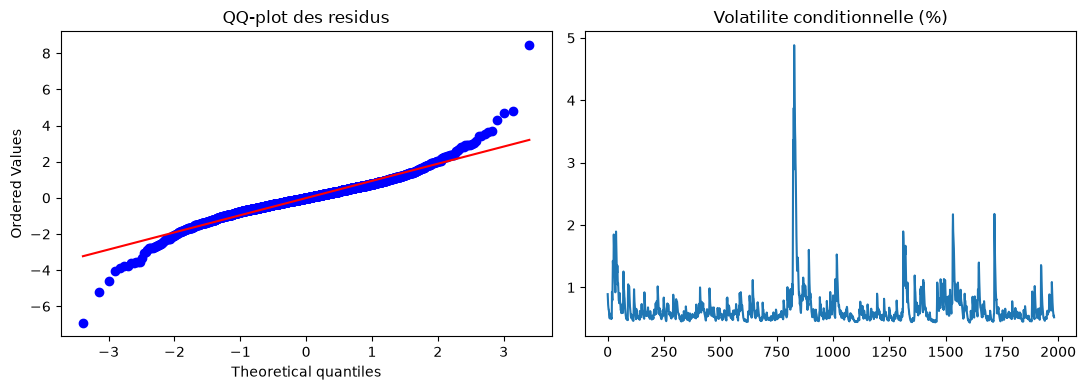

Ljung-Box sur z : {'lb_stat': 56.93420636626515, 'lb_pvalue': 1.371397426800409e-08}
Ljung-Box sur z^2 : {'lb_stat': 1.149305869955158, 'lb_pvalue': 0.9996754047320728}


In [5]:
z = res.std_resid.dropna()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(z, dist="norm", plot=ax[0]); ax[0].set_title("QQ-plot des residus")
ax[1].plot(res.conditional_volatility); ax[1].set_title("Volatilite conditionnelle (%)")
plt.tight_layout()
plt.savefig("../figures/b1_residus_volatilite.png", dpi=150)
plt.show()

print("Ljung-Box sur z :", acorr_ljungbox(z, lags=[10], return_df=True).iloc[0].to_dict())
print("Ljung-Box sur z^2 :", acorr_ljungbox(z ** 2, lags=[10], return_df=True).iloc[0].to_dict())

In [7]:
v = prevoir_volatilites(res, horizon=10)
print(v)

{'vol_1j': 0.5764480783862115, 'vol_5j': 1.3565972916558997, 'vol_10j': 2.0060052657403524, 'vol_annualisee': 9.150829554905897}
